# Reading Zarr arrays and CT volumes
Open a published Zarr group, select a stored pyramid level, read slices and several
blocks, reuse a bounded chunk cache, and reopen cached data offline. These reader
operations also accept a local path or an S3 URL. No PyTorch is needed.


In [1]:
from pathlib import Path
import os

import numpy as np
from _display import panel
from vc_reader import load
from vc_reader.reader import MemoryCache
CACHE = Path(os.environ.get('VC_EXAMPLE_CACHE', '/tmp/vc-reader-notebooks'))
METADATA = os.environ.get('VC_EXAMPLE_METADATA')  # optional local snapshot
options = dict(cache_dir=CACHE, threads=1,
               memory_cache=MemoryCache(64 << 20))
catalog = load(METADATA) if METADATA else load()


## 1. Discover a volume, then open its Zarr group
Discovery identifies the URL; the general reader can also open a caller-provided
`/path/to/volume.zarr`, `https://...` or `s3://...` location. Opening a group reads
metadata. Selecting level 2 uses a stored array and does not resize a level-0 crop.


In [2]:
from vc_reader.reader import ZarrGroup, ZarrReader
volume = catalog.samples['PHercParis4'].volumes['20260411134726']
location = volume.source.storage.location
print('Volume:', volume.id)
print('Location:', location)
with ZarrGroup.open(location, **options) as group:
    print('Stored levels:', group.levels)
    array = group.level(2)
    print('ZYX shape:', array.shape, 'chunks:', array.chunks, 'dtype:', array.dtype)
    array_location = array.location  # direct array URL, for ZarrReader.open below


Volume: 20260411134726
Location: https://vesuvius-challenge-open-data.s3.us-east-1.amazonaws.com/PHercParis4/volumes/20260411134726-2.400um-0.2m-78keV-masked.zarr/
Stored levels: ('0', '1', '2', '3', '4', '5')
ZYX shape: (18946, 8174, 8174) chunks: (128, 128, 128) dtype: uint8


## 2. Read an axial slice and multiple overlapping blocks
Array indexing follows the stored axes (ZYX for this CT). `read(start,size)` and
`read_many` also use those axes. Chunk overlap is shared within the batch and
across calls through the cache; output memory is separate from that cache.


Slice / block: (128, 128) (16, 64, 64)
Batch blocks: [(8, 32, 32), (8, 32, 32)]
Cache/I/O counters: {'memory_hits': 3, 'pending_hits': 0, 'pending_writes': 0, 'disk_hits': 0, 'remote_fetches': 4, 'remote_missing': 0, 'remote_bytes': 8388608, 'write_errors': 0, 'last_write_error': ''}


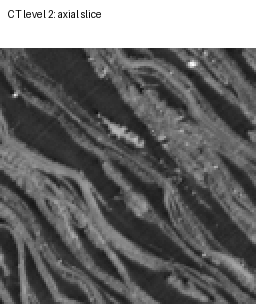

In [3]:
with ZarrReader.open(array_location, **options) as reader:
    axial = reader[9064, 3600:3728, 3600:3728]
    block = reader.read((9056, 3600, 3600), (16, 64, 64))
    regions = [((9056, 3600, 3600), (8, 32, 32)),
               ((9060, 3616, 3616), (8, 32, 32))]
    patches = reader.read_many(regions)
    float_patch = reader.read(*regions[0], dtype=np.float32)
    np.testing.assert_array_equal(float_patch, patches[0])
    stats = reader.stats()
print('Slice / block:', axial.shape, block.shape)
print('Batch blocks:', [p.shape for p in patches])
print('Cache/I/O counters:', stats)
display(panel([('CT level 2: axial slice', axial.astype(np.float32)/255)]))


## 3. Reuse a destination buffer and reopen offline
Explicit `out` buffers avoid repeated output allocation in a loop. Here we keep
the returned data only until the next write to the same buffer. Offline opening
requires cached headers **and** the chunks requested; it does not download them.


In [4]:
buffer = np.empty((8, 32, 32), dtype=np.float32)
with ZarrReader.open(array_location, **options) as reader:
    returned = reader.read((9056, 3600, 3600), buffer.shape, out=buffer, dtype=np.float32)
    assert np.shares_memory(returned, buffer)
    expected = buffer.copy()
with ZarrReader.open(array_location, **{**options, 'offline': True}) as reader:
    cached = reader.read((9056, 3600, 3600), buffer.shape, dtype=np.float32)
np.testing.assert_array_equal(cached, expected)
print('Offline crop equals online/cached crop; shared cache bytes:', options['memory_cache'].nbytes)


Offline crop equals online/cached crop; shared cache bytes: 8388608


## 4. Read through a discovered volume instead
Use the browsing view when you want catalog ownership and stored-level selection.
Use `ZarrGroup`/`ZarrReader` for general arrays. Both paths reuse the same storage
reader. Use context managers so reader resources are closed promptly.


In [5]:
with volume.open(level=2, **options) as reader:
    discovered = reader.read((9056, 3600, 3600), (8, 32, 32))
np.testing.assert_array_equal(discovered, patches[0])
print('Catalog and direct Zarr reads agree.')


Catalog and direct Zarr reads agree.
